PART A- Blessing

Installing Packages and importing libraries- Blessing

In [ ]:
%pip -q install pyspark ucimlrepo

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml import Pipeline

from pyspark.ml.evaluation import (
    BinaryClassificationEvaluator,
    MulticlassClassificationEvaluator
)

from pyspark.ml.stat import Correlation

from ucimlrepo import fetch_ucirepo

Downloading the dataset

In [ ]:
# Download dataset from UCI
cdc_data = fetch_ucirepo(id=891)

# Features
X = cdc_data.data.features

# Target
y = cdc_data.data.targets

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

X.head()

Feature shape: (253680, 21)
Target shape: (253680, 1)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1,1,1,40,1,0,0,0,0,1,...,1,0,5,18,15,1,0,9,4,3
1,0,0,0,25,1,0,0,1,0,0,...,0,1,3,0,0,0,0,7,6,1
2,1,1,1,28,0,0,0,0,1,0,...,1,1,5,30,30,1,0,9,4,8
3,1,0,1,27,0,0,0,1,1,1,...,1,0,2,0,0,0,0,11,3,6
4,1,1,1,24,0,0,0,1,1,1,...,1,0,2,3,0,0,0,11,5,4


In [ ]:
# Combining features and target
pdf = pd.concat([y, X], axis=1)

print("Dataset shape:", pdf.shape)
print("\nColumns:")
print(pdf.columns.tolist())

pdf.head()

Dataset shape: (253680, 22)

Columns:
['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,1,1,1,40,1,0,0,0,0,...,1,0,5,18,15,1,0,9,4,3
1,0,0,0,0,25,1,0,0,1,0,...,0,1,3,0,0,0,0,7,6,1
2,0,1,1,1,28,0,0,0,0,1,...,1,1,5,30,30,1,0,9,4,8
3,0,1,0,1,27,0,0,0,1,1,...,1,0,2,0,0,0,0,11,3,6
4,0,1,1,1,24,0,0,0,1,1,...,1,0,2,3,0,0,0,11,5,4


In [ ]:
#saving to csv
pdf.to_csv("cdc_diabetes_health_indicators.csv", index=False)

print("CSV saved successfully.")

CSV saved successfully.


Creating the Spark session

In [ ]:
spark = (
    SparkSession.builder
    .appName("CDC_Diabetes_Project")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Spark version:", spark.version)

Spark version: 4.0.4


Converting dataset to Spark

In [ ]:
df = spark.createDataFrame(pdf)

print("Number of records:", df.count())
print("Number of columns:", len(df.columns))

Number of records: 253680
Number of columns: 22


In [ ]:
#Inspecting the data
df.show(5)
df.printSchema()

+---------------+------+--------+---------+---+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+---+---------+------+
|Diabetes_binary|HighBP|HighChol|CholCheck|BMI|Smoker|Stroke|HeartDiseaseorAttack|PhysActivity|Fruits|Veggies|HvyAlcoholConsump|AnyHealthcare|NoDocbcCost|GenHlth|MentHlth|PhysHlth|DiffWalk|Sex|Age|Education|Income|
+---------------+------+--------+---------+---+------+------+--------------------+------------+------+-------+-----------------+-------------+-----------+-------+--------+--------+--------+---+---+---------+------+
|              0|     1|       1|        1| 40|     1|     0|                   0|           0|     0|      1|                0|            1|          0|      5|      18|      15|       1|  0|  9|        4|     3|
|              0|     0|       0|        0| 25|     1|     0|                   0|           1|     0|      0|                0|            

In [ ]:
#examining the columns
print(df.columns)

['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


PART B- Blessing

DATA PREPROCESSING-Blessing

In [ ]:
#Checking for missing values
# Checking for missing values
df.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c)
    for c in df.columns
]).show(vertical=True)

-RECORD 0-------------------
 Diabetes_binary      | 0   
 HighBP               | 0   
 HighChol             | 0   
 CholCheck            | 0   
 BMI                  | 0   
 Smoker               | 0   
 Stroke               | 0   
 HeartDiseaseorAttack | 0   
 PhysActivity         | 0   
 Fruits               | 0   
 Veggies              | 0   
 HvyAlcoholConsump    | 0   
 AnyHealthcare        | 0   
 NoDocbcCost          | 0   
 GenHlth              | 0   
 MentHlth             | 0   
 PhysHlth             | 0   
 DiffWalk             | 0   
 Sex                  | 0   
 Age                  | 0   
 Education            | 0   
 Income               | 0   



In [ ]:
#Removing duplicates
original_count = df.count()
df = df.dropDuplicates()
clean_count = df.count()
print("Original rows:", original_count)
print("Rows after removing duplicates:", clean_count)
print("Duplicates removed:", original_count - clean_count)

Original rows: 253680
Rows after removing duplicates: 229474
Duplicates removed: 24206


In [ ]:
#Converting the columns to double to create numeric columns
for column in df.columns:
    df = df.withColumn(column, F.col(column).cast("double"))

df.printSchema()

root
 |-- Diabetes_binary: double (nullable = true)
 |-- HighBP: double (nullable = true)
 |-- HighChol: double (nullable = true)
 |-- CholCheck: double (nullable = true)
 |-- BMI: double (nullable = true)
 |-- Smoker: double (nullable = true)
 |-- Stroke: double (nullable = true)
 |-- HeartDiseaseorAttack: double (nullable = true)
 |-- PhysActivity: double (nullable = true)
 |-- Fruits: double (nullable = true)
 |-- Veggies: double (nullable = true)
 |-- HvyAlcoholConsump: double (nullable = true)
 |-- AnyHealthcare: double (nullable = true)
 |-- NoDocbcCost: double (nullable = true)
 |-- GenHlth: double (nullable = true)
 |-- MentHlth: double (nullable = true)
 |-- PhysHlth: double (nullable = true)
 |-- DiffWalk: double (nullable = true)
 |-- Sex: double (nullable = true)
 |-- Age: double (nullable = true)
 |-- Education: double (nullable = true)
 |-- Income: double (nullable = true)



In [ ]:
#Checking target distribution
df.groupBy("Diabetes_binary") \
  .count() \
  .orderBy("Diabetes_binary") \
  .show()

+---------------+------+
|Diabetes_binary| count|
+---------------+------+
|            0.0|194377|
|            1.0| 35097|
+---------------+------+



In [ ]:
#Percentages
# Calculating diabetes class distribution and percentages
total = df.count()

df.groupBy("Diabetes_binary").count() \
  .withColumn("Percentage", F.round(F.col("count") / total * 100, 2)) \
  .show()

+---------------+------+----------+
|Diabetes_binary| count|Percentage|
+---------------+------+----------+
|            0.0|194377|     84.71|
|            1.0| 35097|     15.29|
+---------------+------+----------+



In [ ]:
#Descriptive statistics
selected_variables = ["BMI","Age","GenHlth","MentHlth","PhysHlth"]
df.select(selected_variables).describe().show()

+-------+------------------+------------------+------------------+------------------+-----------------+
|summary|               BMI|               Age|           GenHlth|          MentHlth|         PhysHlth|
+-------+------------------+------------------+------------------+------------------+-----------------+
|  count|            229474|            229474|            229474|            229474|           229474|
|   mean|28.687507081412274| 8.085068460914963|2.6018198140094304|3.5098660414687504|4.681218787313595|
| stddev| 6.789204221543239|3.0944513703576435|1.0649620814999685| 7.717643069178907| 9.05087733033701|
|    min|              12.0|               1.0|               1.0|               0.0|              0.0|
|    max|              98.0|              13.0|               5.0|              30.0|             30.0|
+-------+------------------+------------------+------------------+------------------+-----------------+



PART C-Blessing

Statistical and correlation Analysis

In [ ]:
#Comparing BMI by diabetes status
df.groupBy("Diabetes_binary").agg(
    F.count("*").alias("N"),
    F.round(F.mean("BMI"), 2).alias("Mean_BMI"),
    F.round(F.stddev("BMI"), 2).alias("SD_BMI")
).show()

+---------------+------+--------+------+
|Diabetes_binary|     N|Mean_BMI|SD_BMI|
+---------------+------+--------+------+
|            0.0|194377|    28.1|   6.5|
|            1.0| 35097|   31.96|  7.38|
+---------------+------+--------+------+



In [ ]:
#Comparing Age
df.groupBy("Diabetes_binary").agg(
    F.round(F.mean("Age"), 2).alias("Mean_Age"),
    F.round(F.stddev("Age"), 2).alias("SD_Age")
).show()

+---------------+--------+------+
|Diabetes_binary|Mean_Age|SD_Age|
+---------------+--------+------+
|            0.0|    7.85|  3.16|
|            1.0|    9.38|  2.33|
+---------------+--------+------+



In [ ]:
#Important Risk factors
risk_factors = ["HighBP", "HighChol", "Smoker", "Stroke",
                "HeartDiseaseorAttack", "PhysActivity"]

for factor in risk_factors:
    print(f"\n{factor}")
    df.groupBy("Diabetes_binary", factor).count().show()


HighBP
+---------------+------+------+
|Diabetes_binary|HighBP| count|
+---------------+------+------+
|            1.0|   1.0| 26405|
|            0.0|   1.0| 77855|
|            1.0|   0.0|  8692|
|            0.0|   0.0|116522|
+---------------+------+------+


HighChol
+---------------+--------+------+
|Diabetes_binary|HighChol| count|
+---------------+--------+------+
|            1.0|     1.0| 23496|
|            0.0|     1.0| 77849|
|            1.0|     0.0| 11601|
|            0.0|     0.0|116528|
+---------------+--------+------+


Smoker
+---------------+------+------+
|Diabetes_binary|Smoker| count|
+---------------+------+------+
|            1.0|   1.0| 18223|
|            0.0|   1.0| 88666|
|            1.0|   0.0| 16874|
|            0.0|   0.0|105711|
+---------------+------+------+


Stroke
+---------------+------+------+
|Diabetes_binary|Stroke| count|
+---------------+------+------+
|            1.0|   1.0|  3268|
|            0.0|   1.0|  7016|
|            1.0|  

Correlation with diabetes

In [ ]:
analysis_variables = ["Diabetes_binary","HighBP","HighChol","BMI","Smoker","Stroke","HeartDiseaseorAttack","PhysActivity","Fruits","Veggies","HvyAlcoholConsump","AnyHealthcare","NoDocbcCost","GenHlth","MentHlth","PhysHlth","DiffWalk","Sex","Age","Education","Income"]

In [ ]:
#creating a feature vector
correlation_assembler = VectorAssembler(inputCols=analysis_variables,outputCol="corr_features")
corr_df = correlation_assembler.transform(df)

In [ ]:
#correlation matrix
correlation_matrix = (Correlation.corr(corr_df,"corr_features",method="pearson").head()[0].toArray())
correlation_matrix

array([[ 1.        ,  0.25431802,  0.19494411,  0.20508596,  0.04550399,
         0.0991933 ,  0.16821317, -0.10040433, -0.02480534, -0.04173376,
        -0.06595002,  0.02533134,  0.02004828,  0.27693982,  0.05415268,
         0.15621083,  0.20530219,  0.03272416,  0.17726335, -0.10268615,
        -0.14065874],
       [ 0.25431802,  1.        ,  0.28396256,  0.19421843,  0.07426414,
         0.12455843,  0.20144344, -0.10438234, -0.01946669, -0.04299382,
        -0.01417836,  0.05204384,  0.00229219,  0.27278369,  0.03748179,
         0.14465605,  0.21175921,  0.04711917,  0.33980204, -0.11288704,
        -0.14002957],
       [ 0.19494411,  0.28396256,  1.        ,  0.08973421,  0.07458259,
         0.08937513,  0.17644616, -0.06344274, -0.02625714, -0.0273994 ,
        -0.01905654,  0.0523626 ,  0.0030197 ,  0.18813852,  0.05034611,
         0.11100754,  0.13604475,  0.0228595 ,  0.26384095, -0.05004535,
        -0.06208931],
       [ 0.20508596,  0.19421843,  0.08973421,  1.        

In [ ]:
#converting the matrix to a table
corr_pd = pd.DataFrame(correlation_matrix,columns=analysis_variables,index=analysis_variables)
corr_pd.round(3)

,Diabetes_binary,HighBP,HighChol,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
Diabetes_binary,1.000,0.254,0.195,0.205,0.046,0.099,0.168,-0.100,-0.025,-0.042,...,0.025,0.020,0.277,0.054,0.156,0.205,0.033,0.177,-0.103,-0.141
HighBP,0.254,1.000,0.284,0.194,0.074,0.125,0.201,-0.104,-0.019,-0.043,...,0.052,0.002,0.273,0.037,0.145,0.212,0.047,0.340,-0.113,-0.140
HighChol,0.195,0.284,1.000,0.090,0.075,0.089,0.176,-0.063,-0.026,-0.027,...,0.052,0.003,0.188,0.050,0.111,0.136,0.023,0.264,-0.050,-0.062
BMI,0.205,0.194,0.090,1.000,-0.009,0.011,0.040,-0.128,-0.067,-0.044,...,-0.009,0.046,0.208,0.069,0.103,0.183,0.031,-0.049,-0.074,-0.069
Smoker,0.046,0.074,0.075,-0.009,1.000,0.054,0.105,-0.067,-0.062,-0.014,...,-0.014,0.037,0.135,0.078,0.100,0.108,0.097,0.108,-0.136,-0.095
Stroke,0.099,0.125,0.089,0.011,0.054,1.000,0.199,-0.059,-0.004,-0.033,...,0.014,0.029,0.170,0.062,0.141,0.169,0.004,0.128,-0.064,-0.117
HeartDiseaseorAttack,0.168,0.201,0.176,0.040,0.105,0.199,1.000,-0.073,-0.007,-0.027,...,0.026,0.022,0.246,0.053,0.170,0.203,0.090,0.224,-0.082,-0.123
PhysActivity,-0.100,-0.104,-0.063,-0.128,-0.067,-0.059,-0.073,1.000,0.125,0.135,...,0.024,-0.046,-0.238,-0.106,-0.199,-0.236,0.034,-0.088,0.171,0.166
Fruits,-0.025,-0.019,-0.026,-0.067,-0.062,-0.004,-0.007,0.125,1.000,0.243,...,0.023,-0.032,-0.071,-0.052,-0.024,-0.030,-0.089,0.074,0.085,0.051
Veggies,-0.042,-0.043,-0.027,-0.044,-0.014,-0.033,-0.027,0.135,0.243,1.000,...,0.021,-0.020,-0.094,-0.042,-0.045,-0.063,-0.066,-0.004,0.132,0.125


In [ ]:
#Correlation with diabetes
diabetes_correlations = (corr_pd["Diabetes_binary"].drop("Diabetes_binary").sort_values(key=abs, ascending=False))
print(diabetes_correlations)

GenHlth                 0.276940
HighBP                  0.254318
DiffWalk                0.205302
BMI                     0.205086
HighChol                0.194944
Age                     0.177263
HeartDiseaseorAttack    0.168213
PhysHlth                0.156211
Income                 -0.140659
Education              -0.102686
PhysActivity           -0.100404
Stroke                  0.099193
HvyAlcoholConsump      -0.065950
MentHlth                0.054153
Smoker                  0.045504
Veggies                -0.041734
Sex                     0.032724
AnyHealthcare           0.025331
Fruits                 -0.024805
NoDocbcCost             0.020048
Name: Diabetes_binary, dtype: float64


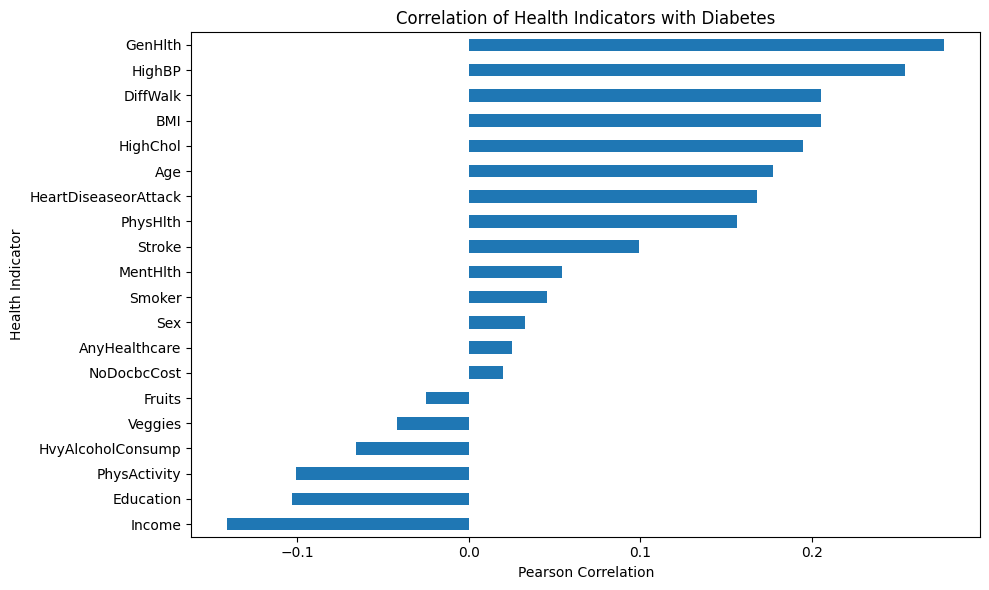

In [ ]:
#correlation plots
plt.figure(figsize=(10, 6))
diabetes_correlations.sort_values().plot(kind="barh")
plt.title("Correlation of Health Indicators with Diabetes")
plt.xlabel("Pearson Correlation")
plt.ylabel("Health Indicator")

plt.tight_layout()
plt.show()

PART D -LEONA

Machine Learning- Leona

Logistic Regression

In [ ]:
#Defining predictors
feature_columns = ["HighBP","HighChol","CholCheck","BMI","Smoker","Stroke","HeartDiseaseorAttack","PhysActivity","Fruits","Veggies","HvyAlcoholConsump","AnyHealthcare","NoDocbcCost","GenHlth","MentHlth","PhysHlth","DiffWalk","Sex","Age","Education","Income"]
print("Number of predictors:", len(feature_columns))

Number of predictors: 21


Splitting the dataset

In [ ]:
#Train/ test split
train_df, test_df = df.randomSplit([0.80, 0.20],seed=42)
print("Training observations:", train_df.count())
print("Testing observations:", test_df.count())

Training observations: 183566
Testing observations: 45908


In [ ]:
#Cache setting
train_df.cache()
test_df.cache()

train_df.count()
test_df.count()

45742

ML Pipeline

In [ ]:
# Vector Assembler
assembler = VectorAssembler(inputCols=feature_columns,outputCol="unscaled_features")
#Standard Scaler
scaler = StandardScaler(inputCol="unscaled_features",outputCol="features",withStd=True,withMean=True)
#Logistic regression
lr = LogisticRegression(featuresCol="features",labelCol="Diabetes_binary",maxIter=50,regParam=0.01)

In [ ]:
#Defining the Pipeline and Training the model
start_time = time.perf_counter()
pipeline = Pipeline(stages=[assembler, scaler, lr])
model = pipeline.fit(train_df)
training_time = time.perf_counter() - start_time

print(f"Model training time: "f"{training_time:.2f} seconds")

Model training time: 49.02 seconds


In [ ]:
#Predictions
predictions = model.transform(test_df)

predictions.select("Diabetes_binary","prediction","probability").show(10, truncate=False)

+---------------+----------+------------------------------------------+
|Diabetes_binary|prediction|probability                               |
+---------------+----------+------------------------------------------+
|0.0            |0.0       |[0.9863404953761554,0.013659504623844576] |
|0.0            |0.0       |[0.9936944818039545,0.006305518196045523] |
|0.0            |0.0       |[0.9973934959079576,0.0026065040920424387]|
|0.0            |0.0       |[0.9838949812147963,0.01610501878520365]  |
|0.0            |0.0       |[0.9844338347432581,0.015566165256741926] |
|0.0            |0.0       |[0.9886374529895751,0.01136254701042494]  |
|0.0            |0.0       |[0.9871480805891837,0.012851919410816315] |
|0.0            |0.0       |[0.9774653814042052,0.022534618595794753] |
|0.0            |0.0       |[0.9905130708252701,0.00948692917472993]  |
|0.0            |0.0       |[0.9116569180952436,0.08834308190475637]  |
+---------------+----------+------------------------------------

Model Evaluation

In [ ]:
auc_evaluator = BinaryClassificationEvaluator(labelCol="Diabetes_binary",rawPredictionCol="rawPrediction",metricName="areaUnderROC")
auc = auc_evaluator.evaluate(predictions)
print("AUC:", round(auc, 4))

AUC: 0.8091


In [ ]:
#Accuracy
accuracy_evaluator = MulticlassClassificationEvaluator(labelCol="Diabetes_binary",predictionCol="prediction",metricName="accuracy")
accuracy = accuracy_evaluator.evaluate(predictions)
print("Accuracy:", round(accuracy, 4))

Accuracy: 0.8525


In [ ]:
#Precision
precision_evaluator = MulticlassClassificationEvaluator(labelCol="Diabetes_binary",predictionCol="prediction",metricName="weightedPrecision")
precision = precision_evaluator.evaluate(predictions)
print("Precision:", round(precision, 4))

Precision: 0.8175


In [ ]:
#Recall
recall_evaluator = MulticlassClassificationEvaluator(labelCol="Diabetes_binary",predictionCol="prediction",metricName="weightedRecall")
recall = recall_evaluator.evaluate(predictions)
print("Recall:", round(recall, 4))

Recall: 0.8525


In [ ]:
#F1 score
f1_evaluator = MulticlassClassificationEvaluator(labelCol="Diabetes_binary",predictionCol="prediction",metricName="f1")
f1 = f1_evaluator.evaluate(predictions)
print("F1 Score:", round(f1, 4))

F1 Score: 0.8122


In [ ]:
#Displaying model results
model_results = pd.DataFrame({
    "Metric": ["AUC", "Accuracy", "Precision", "Recall", "F1 Score"],
    "Score": [auc, accuracy, precision, recall, f1]
})

model_results

,Metric,Score
0,AUC,0.809062
1,Accuracy,0.852477
2,Precision,0.817543
3,Recall,0.852477
4,F1 Score,0.812162


Confusion Matrix

In [ ]:
confusion = (
     predictions
    .groupBy("Diabetes_binary", "prediction")
    .count()
    .orderBy("Diabetes_binary", "prediction")
)

confusion.show()

+---------------+----------+-----+
|Diabetes_binary|prediction|count|
+---------------+----------+-----+
|            0.0|       0.0|38051|
|            0.0|       1.0|  740|
|            1.0|       0.0| 6008|
|            1.0|       1.0|  943|
+---------------+----------+-----+



In [ ]:
#Converting to Pandas
confusion_pd = confusion.toPandas()
confusion_matrix_pd = confusion_pd.pivot(index="Diabetes_binary",columns="prediction",values="count").fillna(0)
confusion_matrix_pd

prediction,0.0,1.0
Diabetes_binary,,
0.0,38051,740
1.0,6008,943


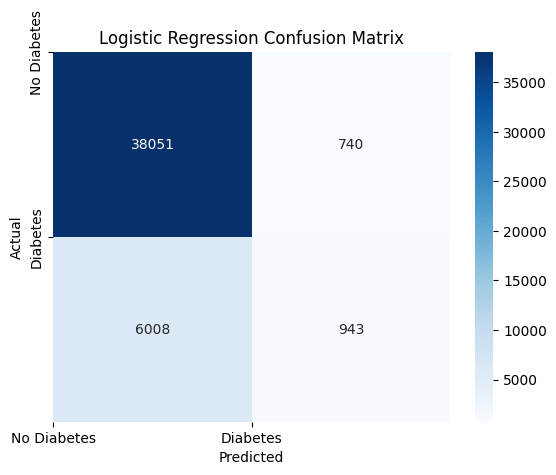

In [ ]:
#Plotting
import seaborn as sns

sns.heatmap(confusion_matrix_pd, annot=True, fmt=".0f", cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ["No Diabetes", "Diabetes"])
plt.yticks([0, 1], ["No Diabetes", "Diabetes"])
plt.show()

ROC Curve

In [ ]:
#Probability Scores
roc_pd = predictions.select("Diabetes_binary","probability").toPandas()
roc_pd["probability_1"] = roc_pd["probability"].apply(lambda x: float(x[1]))

In [ ]:
#ROC Calculation
from sklearn.metrics import roc_curve, auc
fpr, tpr, thresholds = roc_curve(roc_pd["Diabetes_binary"],roc_pd["probability_1"])
roc_auc = auc(fpr, tpr)

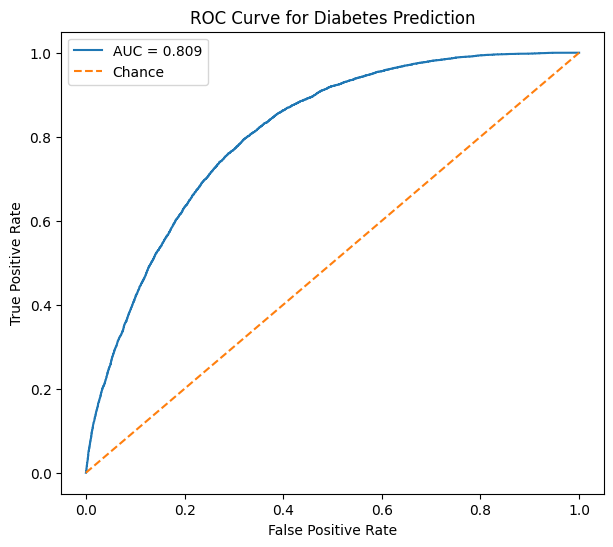

In [ ]:
#Plotting
# Plot ROC curve
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "--", label="Chance")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Diabetes Prediction")
plt.legend()
plt.show()

Logistic Regression Coefficients

In [ ]:
coef_df = pd.DataFrame({"Feature": feature_columns,"Coefficient": model.stages[-1].coefficients.toArray()})
coef_df = coef_df.reindex(coef_df["Coefficient"].abs().sort_values(ascending=False).index)
coef_df

,Feature,Coefficient
13,GenHlth,0.467484
3,BMI,0.360869
0,HighBP,0.349955
18,Age,0.319969
1,HighChol,0.268657
2,CholCheck,0.185511
10,HvyAlcoholConsump,-0.162418
17,Sex,0.117035
20,Income,-0.090863
6,HeartDiseaseorAttack,0.075942


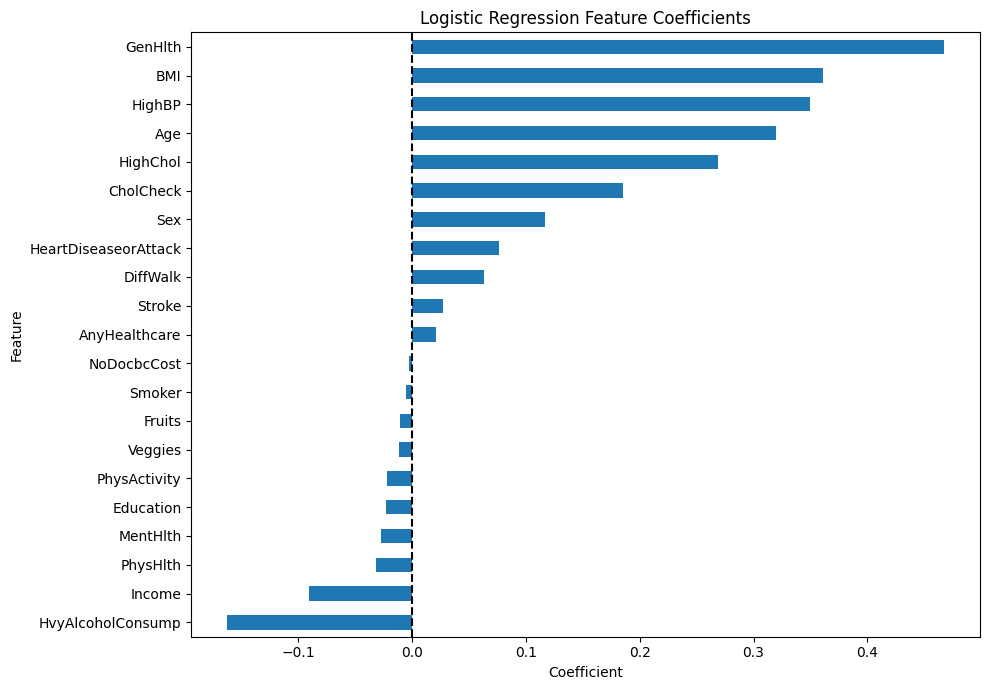

In [ ]:
#Plotting
# Plot logistic regression coefficients
coef_df.sort_values("Coefficient").plot.barh(
    x="Feature", y="Coefficient", figsize=(10, 7), legend=False
)

plt.axvline(0, linestyle="--", color="black")
plt.xlabel("Coefficient")
plt.title("Logistic Regression Feature Coefficients")
plt.tight_layout()
plt.show()

PART E- Leona

Final test set evaluation

In [ ]:
#Test set predictions
# Predict diabetes on the test set
test_predictions = model.transform(test_df)

# Display predictions
test_predictions.select("Diabetes_binary", "prediction", "probability").show(10)

+---------------+----------+--------------------+
|Diabetes_binary|prediction|         probability|
+---------------+----------+--------------------+
|            0.0|       0.0|[0.98634049537615...|
|            0.0|       0.0|[0.99369448180395...|
|            0.0|       0.0|[0.99739349590795...|
|            0.0|       0.0|[0.98389498121479...|
|            0.0|       0.0|[0.98443383474325...|
|            0.0|       0.0|[0.98863745298957...|
|            0.0|       0.0|[0.98714808058918...|
|            0.0|       0.0|[0.97746538140420...|
|            0.0|       0.0|[0.99051307082527...|
|            0.0|       0.0|[0.91165691809524...|
+---------------+----------+--------------------+
only showing top 10 rows


In [ ]:
#Test performance metrics
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
import pandas as pd

# Calculate AUC
auc = BinaryClassificationEvaluator(
    labelCol="Diabetes_binary",
    metricName="areaUnderROC"
).evaluate(test_predictions)

# Calculate other metrics
evaluator = MulticlassClassificationEvaluator(
    labelCol="Diabetes_binary",
    predictionCol="prediction"
)

accuracy = evaluator.evaluate(test_predictions, {evaluator.metricName: "accuracy"})
precision = evaluator.evaluate(test_predictions, {evaluator.metricName: "weightedPrecision"})
recall = evaluator.evaluate(test_predictions, {evaluator.metricName: "weightedRecall"})
f1 = evaluator.evaluate(test_predictions, {evaluator.metricName: "f1"})

# Display results
test_results = pd.DataFrame({
    "Metric": ["AUC", "Accuracy", "Precision", "Recall", "F1 Score"],
    "Test Score": [auc, accuracy, precision, recall, f1]
})

print(test_results.round(3))

      Metric  Test Score
0        AUC       0.809
1   Accuracy       0.852
2  Precision       0.818
3     Recall       0.852
4   F1 Score       0.812


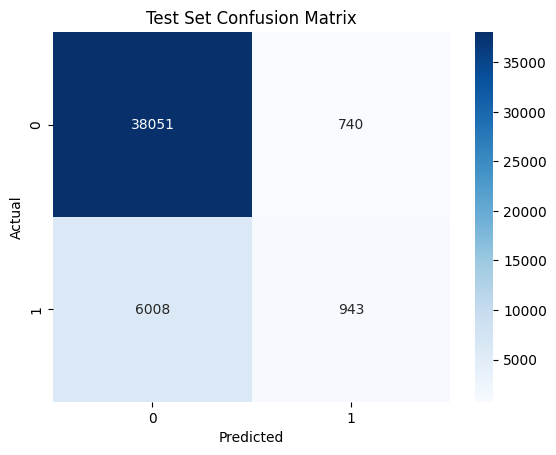

In [ ]:
#Confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Convert actual and predicted labels to pandas
pred_pd = test_predictions.select(
    "Diabetes_binary", "prediction"
).toPandas()

# Confusion matrix
cm = confusion_matrix(
    pred_pd["Diabetes_binary"],
    pred_pd["prediction"],
    labels=[0, 1]
)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[0, 1], yticklabels=[0, 1])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Test Set Confusion Matrix")
plt.show()

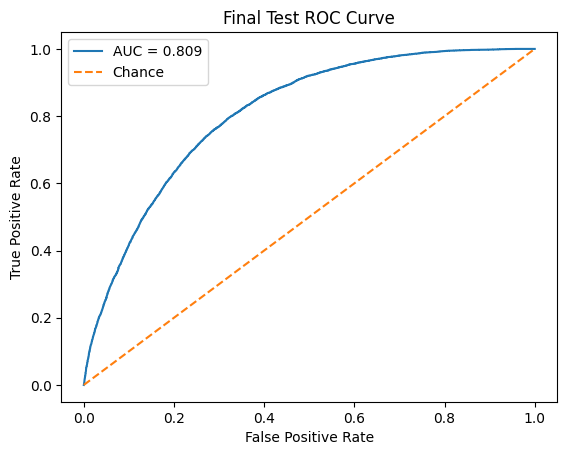

In [ ]:
#Test ROC curve
from sklearn.metrics import roc_curve, roc_auc_score

# Extract probability of diabetes (class 1)
roc_pd = test_predictions.select(
    "Diabetes_binary", "probability"
).toPandas()

y_test = roc_pd["Diabetes_binary"]
y_prob = roc_pd["probability"].apply(lambda x: float(x[1]))

# Calculate ROC
fpr, tpr, _ = roc_curve(y_test, y_prob)
test_auc = roc_auc_score(y_test, y_prob)

# Plot
plt.plot(fpr, tpr, label=f"AUC = {test_auc:.3f}")
plt.plot([0, 1], [0, 1], "--", label="Chance")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Test ROC Curve")
plt.legend()
plt.show()

In [ ]:
#Diabetes-specific performance
from sklearn.metrics import classification_report

print("Final Test Classification Report")
print(classification_report(
    pred_pd["Diabetes_binary"],
    pred_pd["prediction"],
    target_names=["No Diabetes", "Diabetes"],
    zero_division=0
))

Final Test Classification Report
              precision    recall  f1-score   support

 No Diabetes       0.86      0.98      0.92     38791
    Diabetes       0.56      0.14      0.22      6951

    accuracy                           0.85     45742
   macro avg       0.71      0.56      0.57     45742
weighted avg       0.82      0.85      0.81     45742

